# Task 3: Predictive Customer Churn Classifier
### Random Forest & XGBoost

## 1. Introduction

Customer churn refers to the situation where customers stop using a company's products or services. Predicting customer churn helps businesses identify customers who are likely to leave and take preventive actions to retain them.

This project focuses on developing a machine learning-based customer churn prediction system using the Telco Customer Churn dataset.

## 2. Objectives

- Analyze customer subscription records.
- Perform data cleaning and preprocessing.
- Encode categorical features using One-Hot Encoding.
- Handle class imbalance using SMOTE.
- Build Random Forest and XGBoost classifiers.
- Evaluate model performance using ROC-AUC, confusion matrix, and classification metrics.
- Identify the top 10 important features influencing customer churn.

## 3. Technologies Used

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Imbalanced-learn (SMOTE)
- XGBoost
- Jupyter Notebook

## 4. Expected Outcome

Develop an effective customer churn classification model with a ROC-AUC score greater than 80%, helping businesses identify customers at risk of leaving.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("Telco-Customer-Churn.csv")
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (7043, 21)

First 5 Records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

In [2]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')

print("Missing Values:")
display(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate Records:", df.duplicated().sum())

print("\nUpdated Data Types:")
display(df.dtypes)

Missing Values:


TotalCharges    11
dtype: int64


Duplicate Records: 0

Updated Data Types:


customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

In [3]:
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

df.drop('customerID', axis=1, inplace=True)

print("Missing Values After Imputation:", df.isnull().sum().sum())
print("Updated Dataset Shape:", df.shape)

display(df.head())

Missing Values After Imputation: 0
Updated Dataset Shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Churn
No     5174
Yes    1869
Name: count, dtype: int64


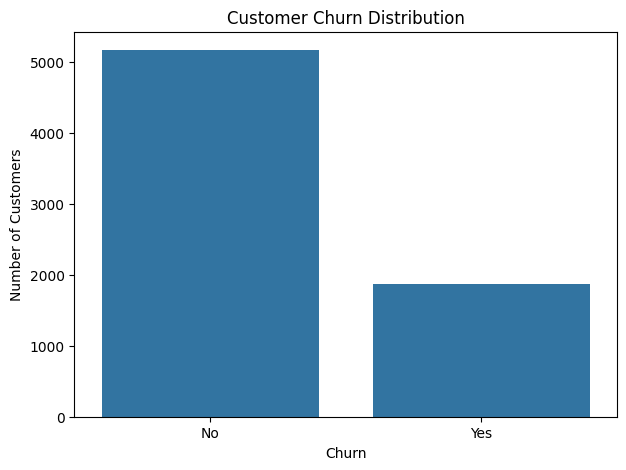


Churn Percentage:


Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [4]:
print(df['Churn'].value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Churn')
plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()

print("\nChurn Percentage:")
display(df['Churn'].value_counts(normalize=True) * 100)

In [5]:
from sklearn.model_selection import train_test_split

X = df.drop('Churn', axis=1)
y = df['Churn'].map({'No': 0, 'Yes': 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("\nTraining Target Distribution:")
display(y_train.value_counts())
print("\nTesting Target Distribution:")
display(y_test.value_counts())

Training Features: (5634, 19)
Testing Features: (1409, 19)

Training Target Distribution:


Churn
0    4139
1    1495
Name: count, dtype: int64


Testing Target Distribution:


Churn
0    1035
1     374
Name: count, dtype: int64

In [6]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_cols = X_train.select_dtypes(include=['object']).columns
numerical_cols = X_train.select_dtypes(exclude=['object']).columns

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('num', 'passthrough', numerical_cols)
    ]
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Encoded Training Shape:", X_train_encoded.shape)
print("Encoded Testing Shape:", X_test_encoded.shape)
print("Number of Categorical Features:", len(categorical_cols))
print("Number of Numerical Features:", len(numerical_cols))

Encoded Training Shape: (5634, 45)
Encoded Testing Shape: (1409, 45)
Number of Categorical Features: 15
Number of Numerical Features: 4


In [8]:
%pip install imbalanced-learn

   ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
   - -------------------------------------- 10.2/236.1 kB ? eta -:--:--
   ------ -------------------------------- 41.0/236.1 kB 653.6 kB/s eta 0:00:01
   --------------- ----------------------- 92.2/236.1 kB 871.5 kB/s eta 0:00:01
   -------------------------- ----------- 163.8/236.1 kB 984.6 kB/s eta 0:00:01
   ---------------------------------------  235.5/236.1 kB 1.1 MB/s eta 0:00:01
   -------------------------------------- 236.1/236.1 kB 903.3 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\gavya\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [9]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_encoded, y_train
)

print("Before SMOTE:")
display(y_train.value_counts())

print("\nAfter SMOTE:")
display(y_train_balanced.value_counts())

print("\nBalanced Training Shape:", X_train_balanced.shape)

Before SMOTE:


Churn
0    4139
1    1495
Name: count, dtype: int64


After SMOTE:


Churn
0    4139
1    4139
Name: count, dtype: int64


Balanced Training Shape: (8278, 45)


In [10]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

rf_model.fit(X_train_balanced, y_train_balanced)

rf_predictions = rf_model.predict(X_test_encoded)
rf_probabilities = rf_model.predict_proba(X_test_encoded)[:, 1]

print("Random Forest Model Training Completed!")
print("Training Samples:", X_train_balanced.shape[0])
print("Testing Samples:", X_test_encoded.shape[0])

Random Forest Model Training Completed!
Training Samples: 8278
Testing Samples: 1409


In [11]:
%pip install xgboost

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB 145.2 kB/s eta 0:11:40
   ---------------------------------------- 0.0/101.7 MB 178.6 kB/s eta 0:09:30
   ---------------------------------------- 0.1/101.7 MB 217.9 kB/s eta 0:07:47
   ---------------------------------------- 0.1/101.7 MB 385.0 kB/s eta 0:04:24
   ---------------------------------------- 0.2/101.7 MB 458.0 kB/s eta 0:03:42
   ---------------------------------------- 0.3/101.7 MB 682.7 kB/s eta 0:02:29
   ---------------------------------------- 0.4/101.7 MB 930.9 kB/s eta 0:01:49
   ---------------------------------------- 0.5/101.7 MB 1.1 MB/s eta 0:01:37
   ---------------------------------------- 0.6/101.7 MB 1.2 MB/s eta 0:01:26



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\gavya\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [12]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_balanced, y_train_balanced)

xgb_predictions = xgb_model.predict(X_test_encoded)
xgb_probabilities = xgb_model.predict_proba(X_test_encoded)[:, 1]

print("XGBoost Model Training Completed!")
print("Training Samples:", X_train_balanced.shape[0])
print("Testing Samples:", X_test_encoded.shape[0])

XGBoost Model Training Completed!
Training Samples: 8278
Testing Samples: 1409


In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

results = []

for name, predictions, probabilities in [
    ("Random Forest", rf_predictions, rf_probabilities),
    ("XGBoost", xgb_predictions, xgb_probabilities)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.7857,0.6000,0.5775,0.5886,0.8326
1,XGBoost,0.7949,0.6246,0.5695,0.5958,0.8433


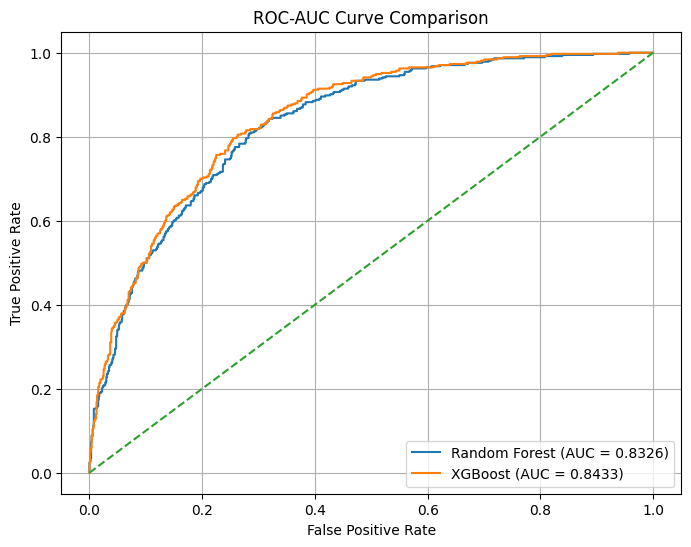

In [14]:
from sklearn.metrics import roc_curve, auc

rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probabilities)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probabilities)

plt.figure(figsize=(8, 6))

plt.plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {auc(rf_fpr, rf_tpr):.4f})')
plt.plot(xgb_fpr, xgb_tpr, label=f'XGBoost (AUC = {auc(xgb_fpr, xgb_tpr):.4f})')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve Comparison')
plt.legend()
plt.grid()
plt.show()

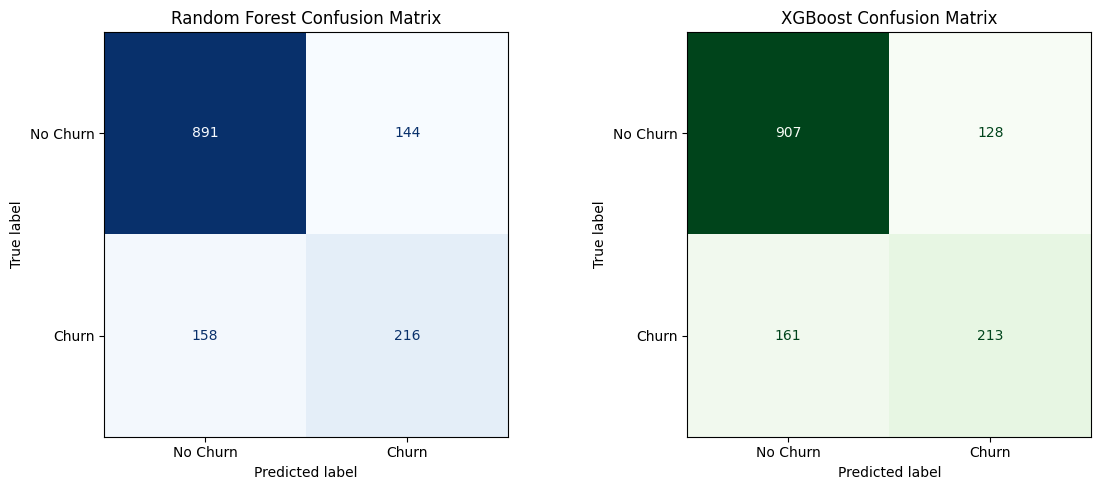

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

rf_cm = confusion_matrix(y_test, rf_predictions)
xgb_cm = confusion_matrix(y_test, xgb_predictions)

ConfusionMatrixDisplay(rf_cm, display_labels=['No Churn', 'Churn']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Random Forest Confusion Matrix')

ConfusionMatrixDisplay(xgb_cm, display_labels=['No Churn', 'Churn']).plot(ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title('XGBoost Confusion Matrix')

plt.tight_layout()
plt.show()

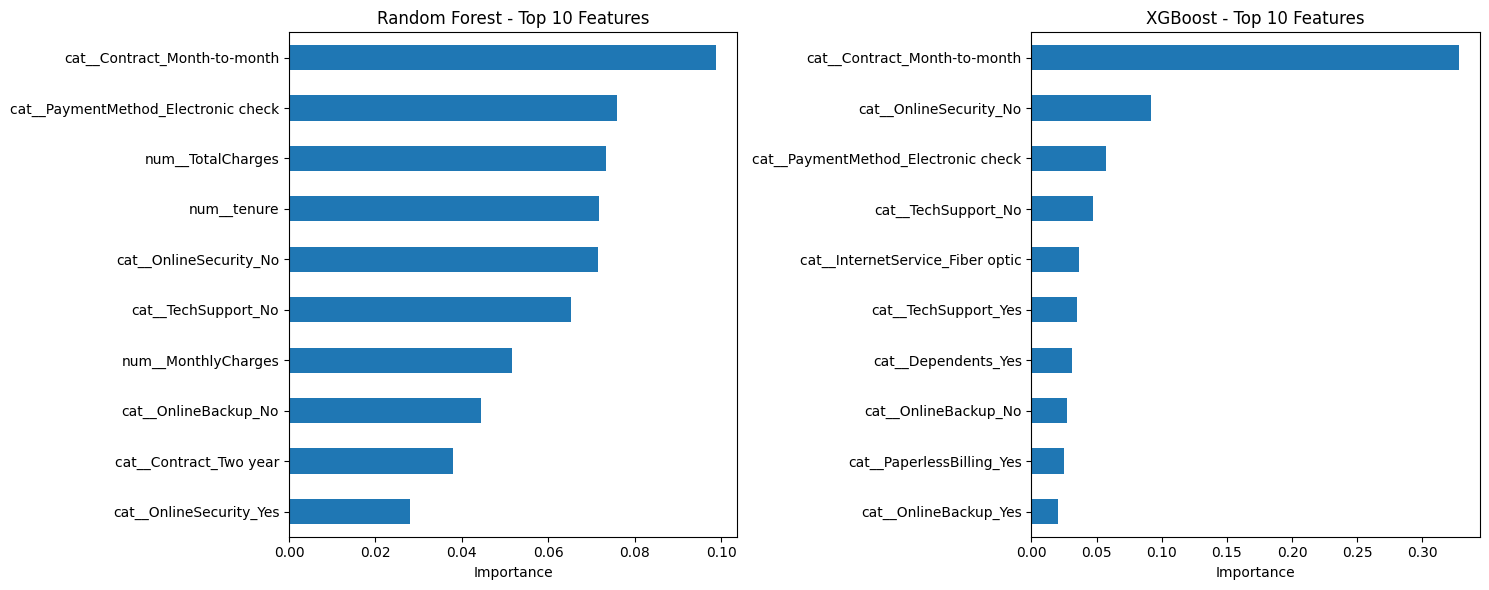

In [16]:
feature_names = preprocessor.get_feature_names_out()

rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_names
).nlargest(10)

xgb_importance = pd.Series(
    xgb_model.feature_importances_,
    index=feature_names
).nlargest(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

rf_importance.sort_values().plot(kind='barh', ax=axes[0])
axes[0].set_title('Random Forest - Top 10 Features')
axes[0].set_xlabel('Importance')

xgb_importance.sort_values().plot(kind='barh', ax=axes[1])
axes[1].set_title('XGBoost - Top 10 Features')
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.show()

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from imblearn.pipeline import Pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1,
        class_weight='balanced'
    ))
])

xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ))
])

rf_cv_scores = cross_val_score(rf_pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
xgb_cv_scores = cross_val_score(xgb_pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)

cv_results = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'Mean ROC-AUC': [rf_cv_scores.mean(), xgb_cv_scores.mean()],
    'Standard Deviation': [rf_cv_scores.std(), xgb_cv_scores.std()]
})

display(cv_results.round(4))

,Model,Mean ROC-AUC,Standard Deviation
0,Random Forest,0.8331,0.0095
1,XGBoost,0.8434,0.0101


In [18]:
from sklearn.metrics import classification_report

print("RANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(y_test, rf_predictions, target_names=['No Churn', 'Churn']))

print("\nXGBOOST CLASSIFICATION REPORT")
print(classification_report(y_test, xgb_predictions, target_names=['No Churn', 'Churn']))

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn       0.85      0.86      0.86      1035
       Churn       0.60      0.58      0.59       374

    accuracy                           0.79      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.79      0.78      1409


XGBOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn       0.85      0.88      0.86      1035
       Churn       0.62      0.57      0.60       374

    accuracy                           0.79      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.79      0.79      1409



In [19]:
final_results = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'Accuracy': [
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, xgb_predictions)
    ],
    'Precision': [
        precision_score(y_test, rf_predictions),
        precision_score(y_test, xgb_predictions)
    ],
    'Recall': [
        recall_score(y_test, rf_predictions),
        recall_score(y_test, xgb_predictions)
    ],
    'F1 Score': [
        f1_score(y_test, rf_predictions),
        f1_score(y_test, xgb_predictions)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, rf_probabilities),
        roc_auc_score(y_test, xgb_probabilities)
    ]
})

display(final_results.round(4))

best_model = final_results.loc[final_results['ROC-AUC'].idxmax(), 'Model']

print("Best Performing Model:", best_model)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.7857,0.6000,0.5775,0.5886,0.8326
1,XGBoost,0.7949,0.6246,0.5695,0.5958,0.8433


Best Performing Model: XGBoost


## 17. Conclusion

The Predictive Customer Churn Classification project successfully developed machine learning models to predict customer attrition using the Telco Customer Churn dataset.

Data preprocessing techniques, including missing value imputation and One-Hot Encoding, were applied to prepare the dataset. SMOTE was used to overcome class imbalance by generating synthetic samples for the minority class.

Two ensemble learning algorithms, Random Forest and XGBoost, were trained and evaluated using accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC.

Among the two models, XGBoost achieved the best overall performance with an accuracy of 79.49% and a ROC-AUC score of 84.33%, exceeding the target of 80%.

The feature importance analysis helped identify the major factors influencing customer churn predictions.

Overall, this project demonstrates how ensemble machine learning techniques can help businesses identify customers at risk of leaving and develop effective customer retention strategies.